Primeiro vamos importar a base montada

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

path_processed = Path(r"..\data") / "processed"
df = pd.read_csv(path_processed / "fakebr_base.csv", encoding='utf-8')
display(df.head())

,index,par_id,rotulo,texto,autor,link,categoria,data,n_tokens,n_palavras,...,n_pron_sing_1_2,n_pron_plur_1,n_pronomes,pausalidade,n_caracteres,tam_medio_sentenca,tam_medio_palavra,erros_ortograficos,emotividade,diversidade
0,0,1,0,﻿O Podemos decidiu expulsar o deputado federa...,Naira Trindade,http://politica.estadao.com.br/blogs/coluna-do...,politica,13/12/2017,168,148,...,0,0,7,3.33333,761.0,24.6667,5.14189,0.000000,0.134328,0.722973
1,1,1,1,Kátia Abreu diz que vai colocar sua expulsão e...,mrk,https://ceticismopolitico.com/2017/11/30/katia...,politica,2017-11-30,211,185,...,2,0,26,2.00000,815.0,14.2308,4.40541,0.000000,0.263158,0.648649
2,2,2,0,Em evento realizado nesta terça-feira para div...,Estadão Conteúdo,http://esportes.estadao.com.br/noticias/futebo...,sociedade_cotidiano,26/12/2017,349,294,...,0,0,29,2.75000,1477.0,14.7000,5.02381,0.000000,0.325758,0.619048
3,3,2,1,Blog esquerdista dá a entender que reclamar de...,NaN,https://ceticismopolitico.com/2017/11/28/blog-...,sociedade_cotidiano,2017-11-28,356,300,...,0,0,30,3.29412,1321.0,17.6471,4.40333,0.013333,0.277372,0.623333
4,4,3,0,﻿Após o prefeito de Manaus Arthur Virgílio (PS...,Juliana Diógenes,"http://politica.estadao.com.br/noticias/geral,...",politica,26/12/2017,249,204,...,3,0,8,3.00000,1019.0,13.6000,4.99510,0.014706,0.160000,0.627451


Vamos observar como o tamanho do texto e numero de tokens varia com a veracidade e categorias.

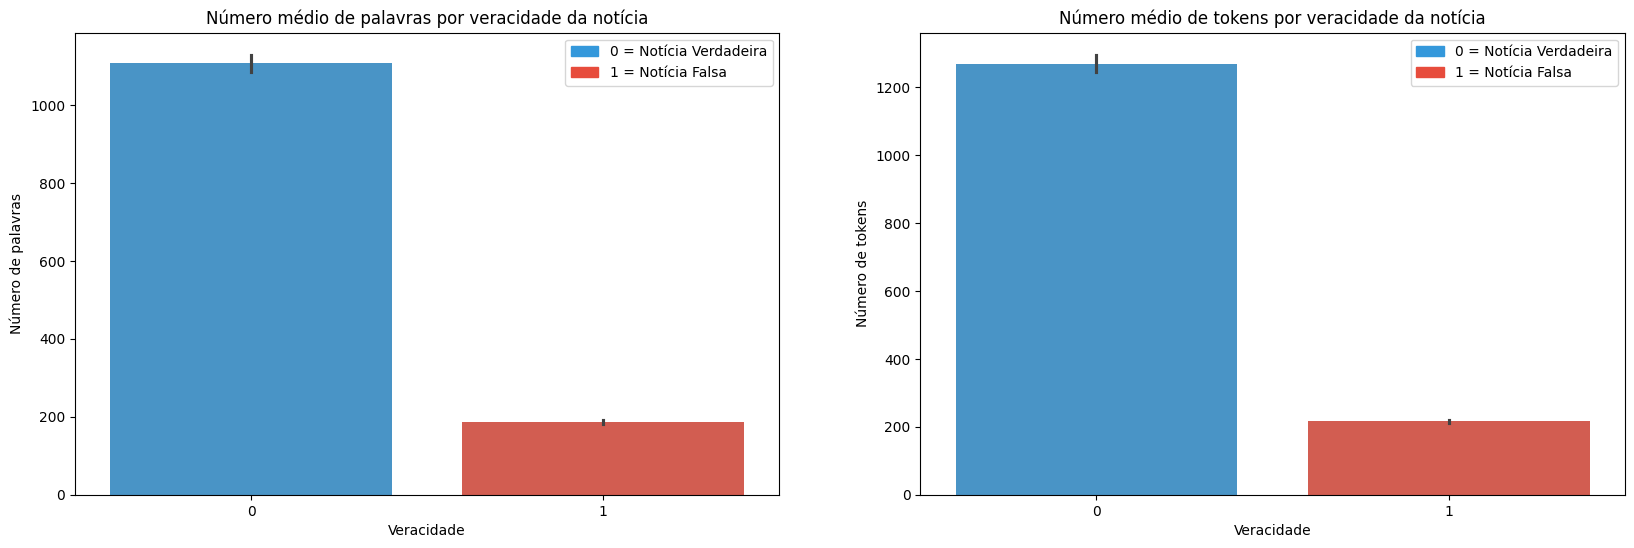

In [2]:
custom_handles = [
    mpatches.Patch(color="#3498db", label="0 = Notícia Verdadeira"),
    mpatches.Patch(color="#e74c3c", label="1 = Notícia Falsa"),
]

palette = {
    0: "#3498db",
    1: "#e74c3c",
}

plt.figure(figsize=(20, 6))

plt.subplot(121)
ax1 = sns.barplot(data=df, x="rotulo", y="n_palavras", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Veracidade")
plt.ylabel("Número de palavras")
plt.title("Número médio de palavras por veracidade da notícia")
ax1.legend(handles=custom_handles, frameon=True)

plt.subplot(122)
ax2 = sns.barplot(data=df, x="rotulo", y="n_tokens", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Veracidade")
plt.ylabel("Número de tokens")
plt.title("Número médio de tokens por veracidade da notícia")
ax2.legend(handles=custom_handles, frameon=True)
plt.show()


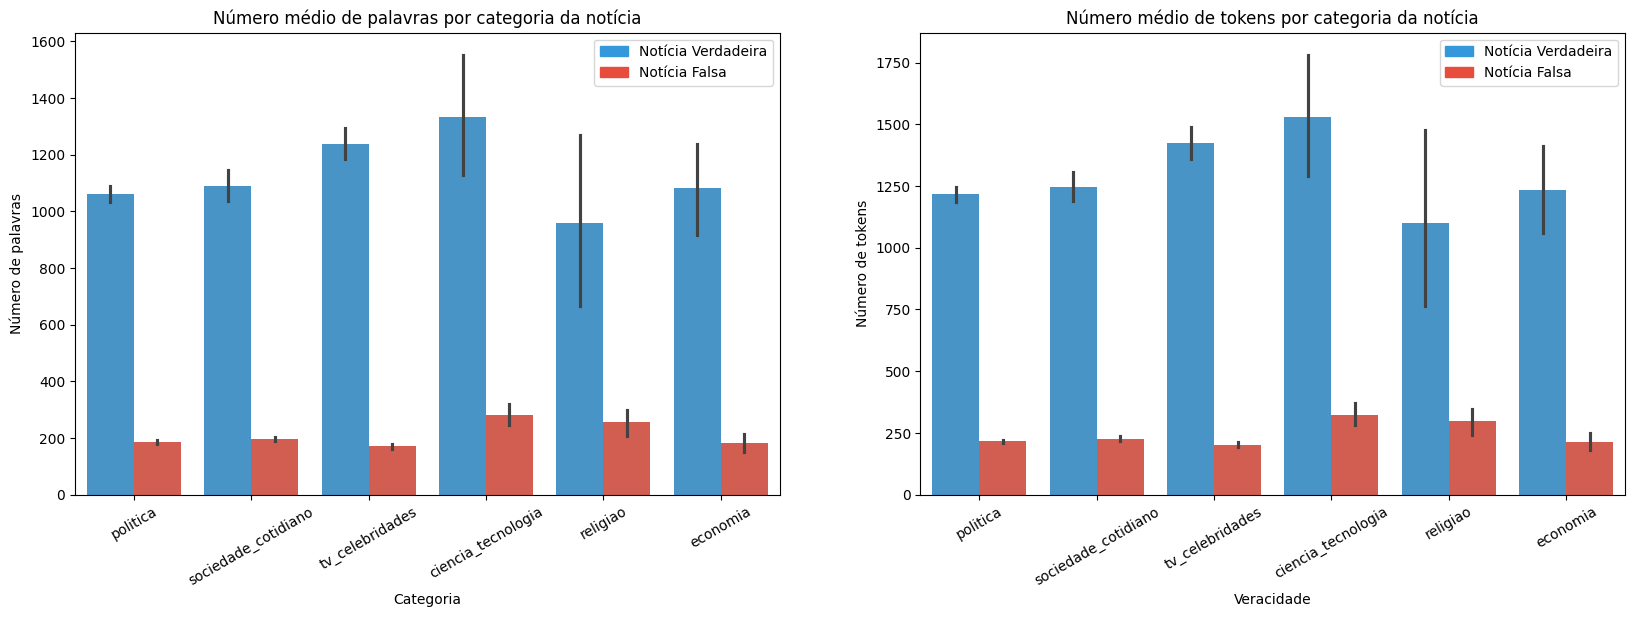

In [3]:
custom_handles = [
    mpatches.Patch(color="#3498db", label="Notícia Verdadeira"),
    mpatches.Patch(color="#e74c3c", label="Notícia Falsa"),
]

plt.figure(figsize=(20, 6))

plt.subplot(121)
ax3 = sns.barplot(data=df, x="categoria", y="n_palavras", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Categoria")
plt.ylabel("Número de palavras")
plt.title("Número médio de palavras por categoria da notícia")
plt.xticks(rotation=30)
ax3.legend(handles=custom_handles, frameon=True)

plt.subplot(122)
ax4 = sns.barplot(data=df, x="categoria", y="n_tokens", legend=False, hue="rotulo", palette=palette)
plt.xlabel("Veracidade")
plt.ylabel("Número de tokens")
plt.title("Número médio de tokens por categoria da notícia")
plt.xticks(rotation=30)
ax4.legend(handles=custom_handles, frameon=True)
plt.show()

Vamos investigar se existe alguma relação entre pausalidade, erros_ortograficos, emotividade, diversidade e  rotulo e  rotulo

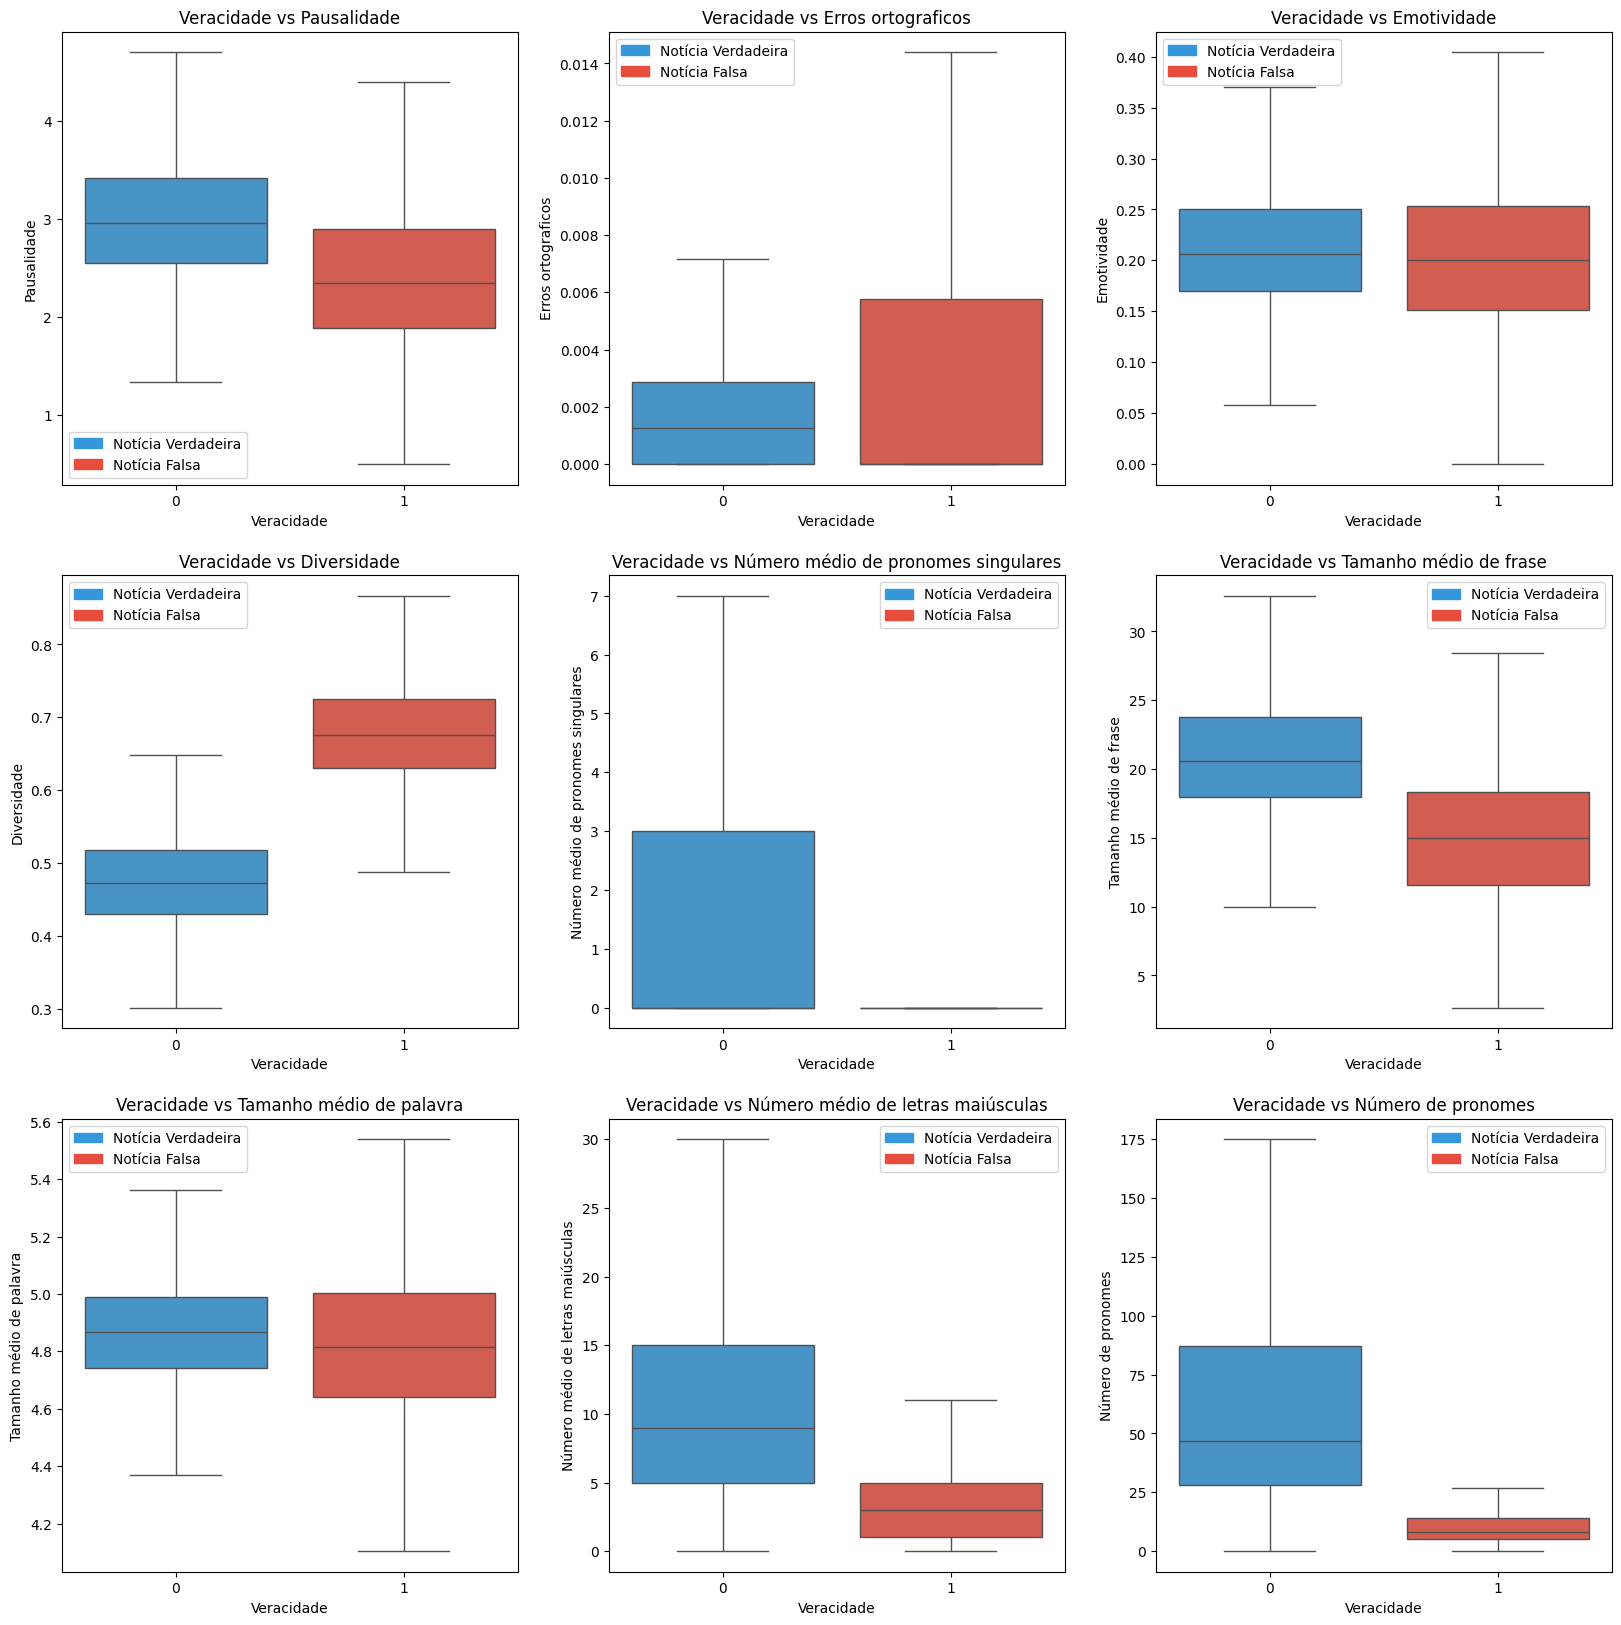

n_pronomes            0.92
n_maiusculas          0.65
tam_medio_sentenca    0.57
pausalidade           0.43
emotividade           0.21
erros_ortograficos    0.20
tam_medio_palavra     0.08
diversidade          -0.93
Name: n_palavras, dtype: float64


In [4]:
columns = ["pausalidade", "erros_ortograficos", "emotividade", "diversidade", "n_pron_sing_1_2", "tam_medio_sentenca", "tam_medio_palavra", "n_maiusculas", "n_pronomes"]

# Só para deixar o título mais bonito
columns_mapping = {
    "pausalidade": "Pausalidade",
    "erros_ortograficos": "Erros ortograficos",
    "emotividade": "Emotividade",
    "diversidade": "Diversidade",
    "n_pron_sing_1_2": "Número médio de pronomes singulares",
    "tam_medio_sentenca": "Tamanho médio de frase",
    "tam_medio_palavra": "Tamanho médio de palavra",
    "n_maiusculas": "Número médio de letras maiúsculas",
    "n_pronomes": "Número de pronomes",
}

plt.figure(figsize=(20, 20))
for i, column in enumerate(columns):
    plt.subplot(330 + i + 1)
    ax = sns.boxplot(data=df, x="rotulo", y=column, hue="rotulo", palette=palette, showfliers=False)
    plt.title(f"Veracidade vs {columns_mapping[column]}")
    plt.xlabel("Veracidade")
    plt.ylabel(columns_mapping[column])
    ax.legend(handles=custom_handles, frameon=True)

plt.show()

variaveis = ["diversidade", "tam_medio_sentenca", "n_maiusculas", "n_pronomes",
             "pausalidade", "emotividade", "erros_ortograficos", "tam_medio_palavra"]

corr_tamanho = (
    df[variaveis + ["n_palavras"]]
    .corr(method="spearman")["n_palavras"]
    .drop("n_palavras")
    .sort_values(ascending=False)
)
print(corr_tamanho.round(2))

As varíaveis com maiores diferenças são na diversidade, tam_medio_sentenca, n_maiusculas e n_pronomes. Vamos investigar se essas variáveis estão correlacionadas com n_palavras.

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


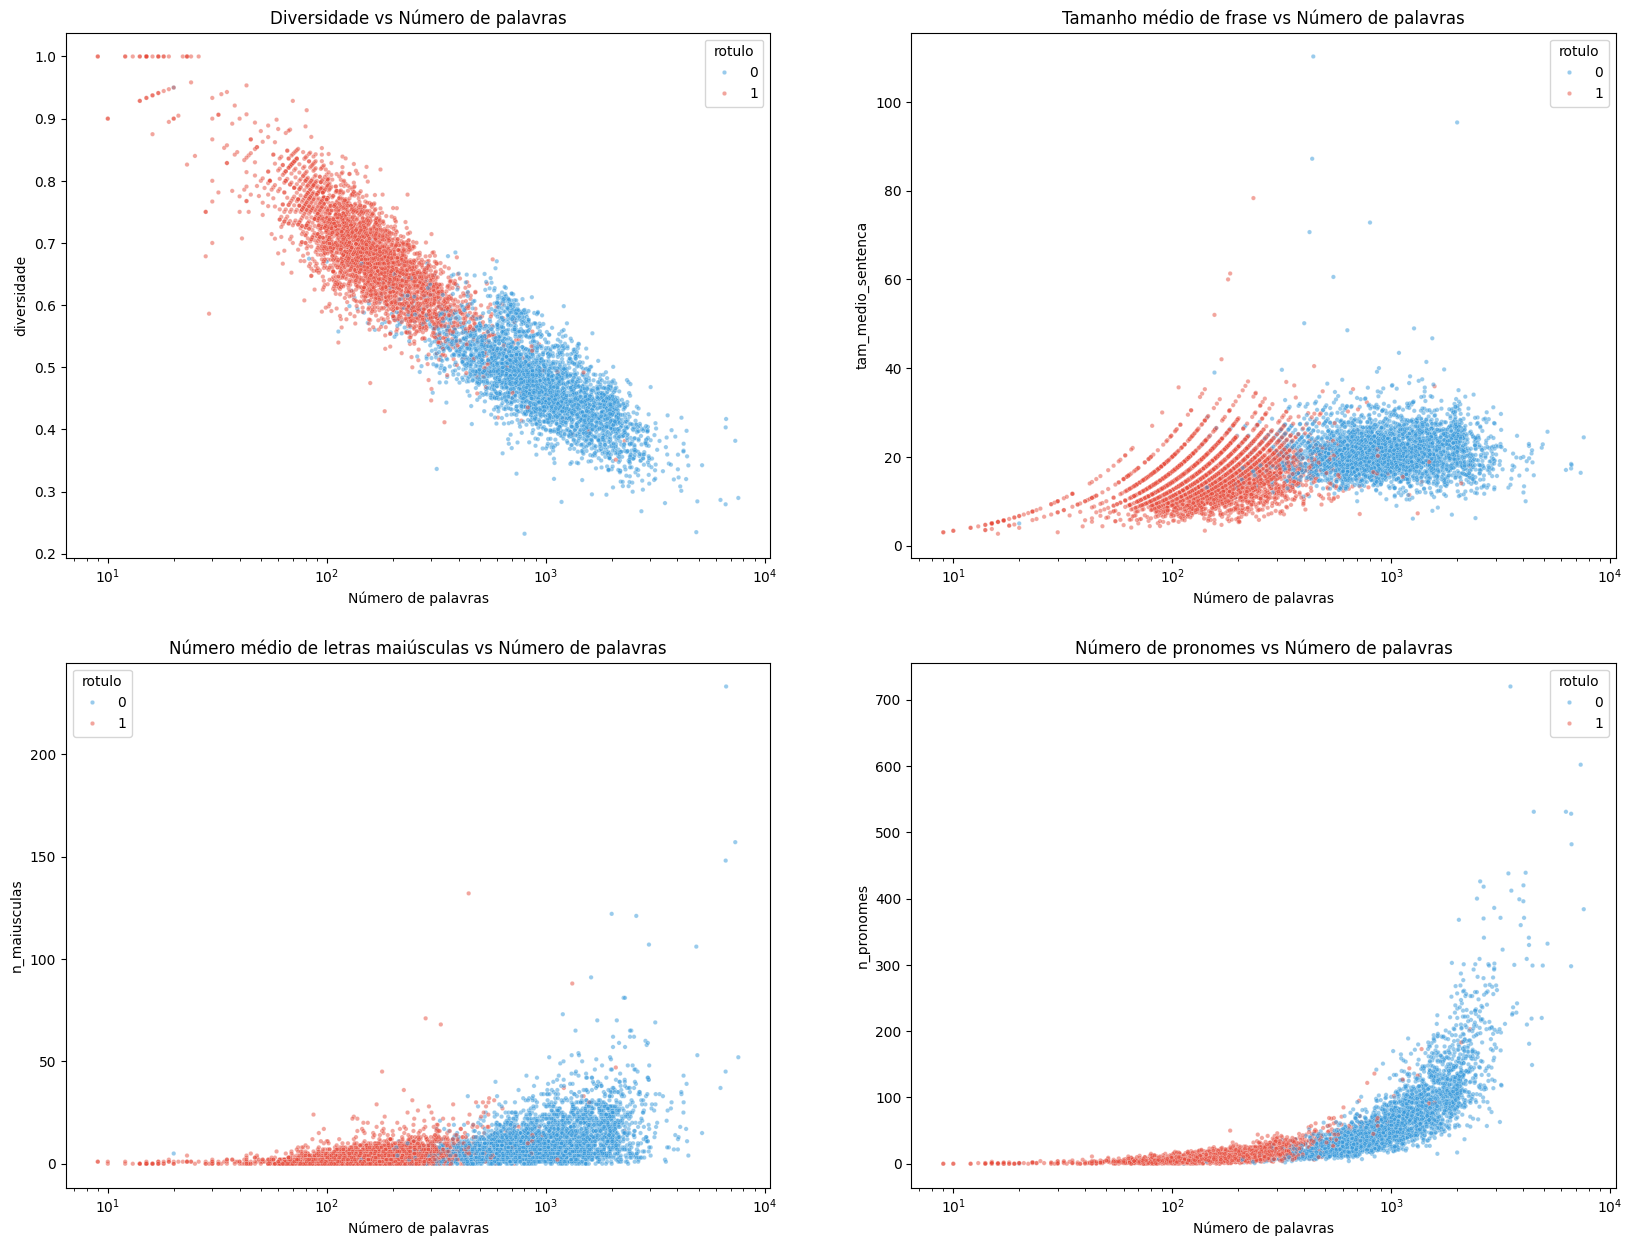

In [5]:
variaveis = ["diversidade", "tam_medio_sentenca", "n_maiusculas", "n_pronomes"]

plt.figure(figsize=(20, 15))

for i, var in enumerate(variaveis):
    plt.subplot(2,2,i + 1)
    sns.scatterplot(data=df, x="n_palavras", y=var, hue="rotulo", palette=palette, alpha=0.5, s=10)
    plt.xscale("log")
    plt.title(f"{columns_mapping[var]} vs Número de palavras")
    plt.xlabel("Número de palavras")
    plt.ylabel(var)
plt.show()

Vamos fazer um heatmap para ver se as varíaveis que são scores variam conforme a categoria da notícia.

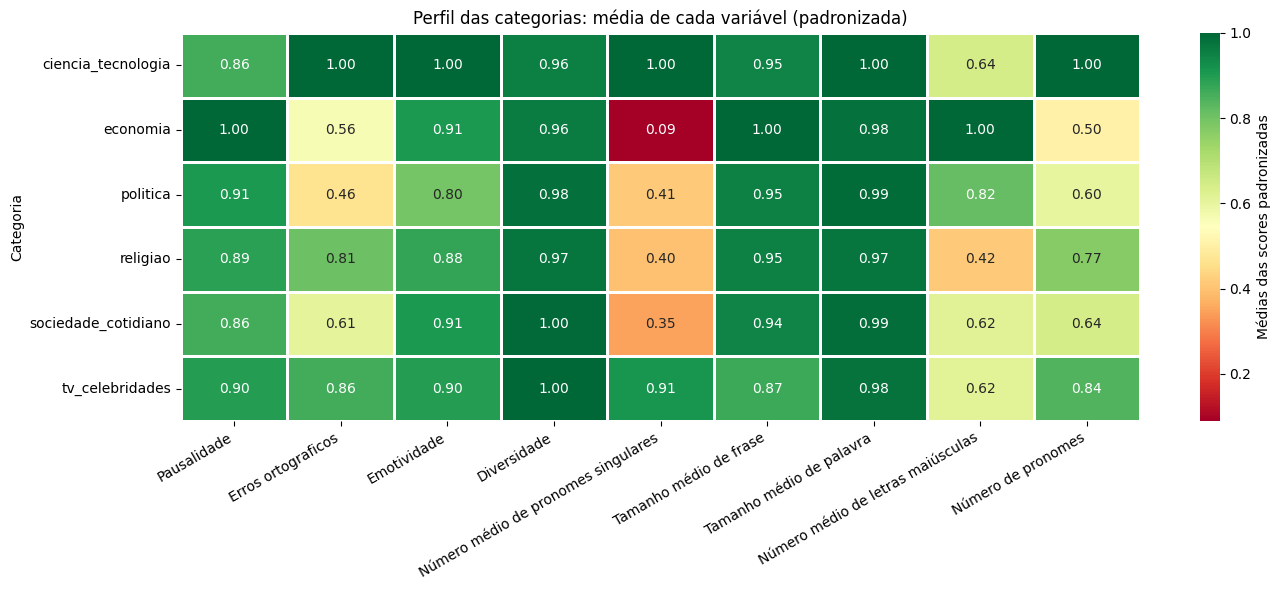

In [6]:
# Média de cada variável por categoria
medias = df.groupby("categoria")[columns].mean()

# Padroniza em relação à base inteira, pois as variáveis têm escalas muito diferentes
medias_norm = medias / medias.max()

plt.figure(figsize=(14, 6))
ax = sns.heatmap(
    medias_norm.rename(columns=columns_mapping),
    cmap="RdYlGn",
    annot=True,
    fmt=".2f",
    linewidths=2,
    linecolor="white",
    cbar_kws={"label": "Médias das scores padronizadas"},
)
ax.set_title("Perfil das categorias: média de cada variável (padronizada)")
ax.set_xlabel("")
ax.set_ylabel("Categoria")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

<b><h3>Engenharia de features</h3></b>

Sabemos que o tamanho do texto influencia muito em varias features, então precisamos fazer engenharia de feature para converter essas contagens em taxas

In [7]:
contagens = ["n_verbos", "n_subj_imp", "n_substantivos", "n_adjetivos", "n_adverbios",
             "n_modais", "n_pron_sing_1_2", "n_pron_plur_1", "n_pronomes",
             "n_maiusculas", "n_links"]
for c in contagens:
    df[f"taxa_{c[2:]}"] = 100 * df[c] / df["n_palavras"]

Agora vamos refazer os boxplots com elas

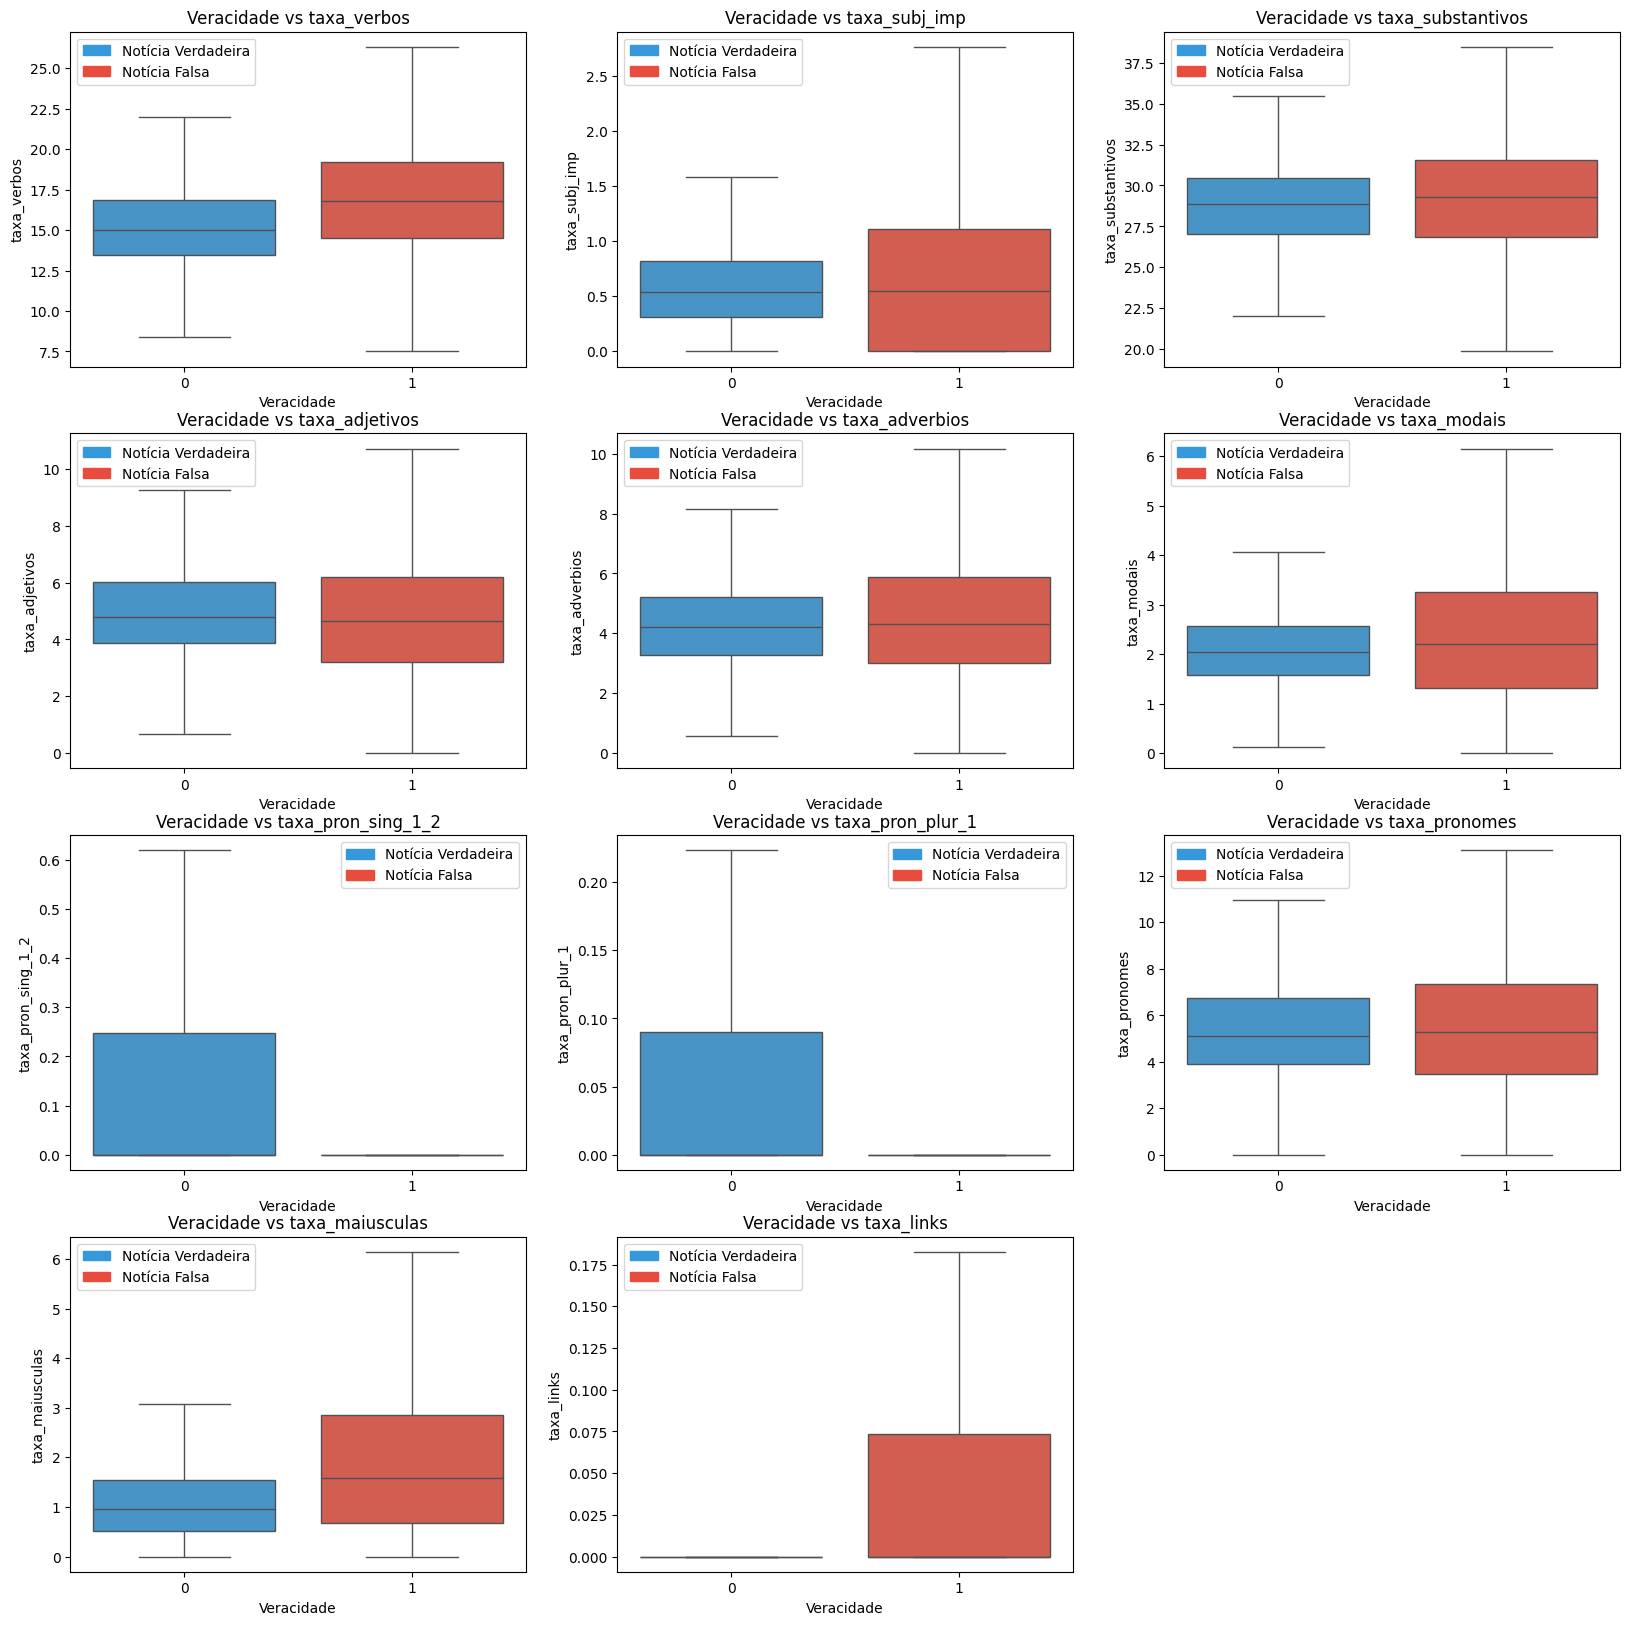

In [8]:
plt.figure(figsize=(20, 20))
for i, column in enumerate(contagens):
    plt.subplot(4,3,i + 1)
    ax = sns.boxplot(data=df, x="rotulo", y=f'taxa_{column[2:]}', hue="rotulo", palette=palette, showfliers=False)
    plt.title(f"Veracidade vs {f'taxa_{column[2:]}'}")
    plt.xlabel("Veracidade")
    plt.ylabel(f'taxa_{column[2:]}')
    ax.legend(handles=custom_handles, frameon=True)

plt.show()

Diversidade também depende de tamanho, então vamos separar a base em faixas de palavras e investigar como a diversidade varia conforme rótulo para cada taxa

,media_true,media_fake,n_true,n_fake,diferenca
faixa,,,,,
"(197.0, 220.0]",0.595,0.648,19,238,0.053
"(220.0, 246.0]",0.603,0.636,23,219,0.033
"(246.0, 282.0]",0.578,0.618,21,217,0.040
"(282.0, 326.0]",0.561,0.608,53,189,0.047
"(326.0, 392.0]",0.549,0.589,108,136,0.040
"(392.0, 478.0]",0.535,0.580,172,75,0.045
"(478.0, 564.0]",0.519,0.539,202,40,0.021
"(564.0, 635.0]",0.515,0.551,229,14,0.036


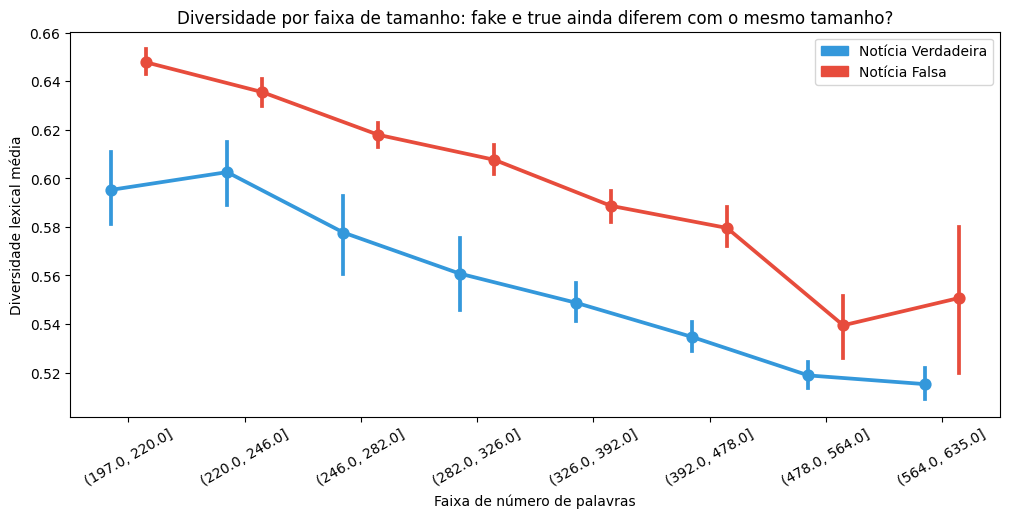

In [9]:
# intervalo de tamanho onde existem textos das duas classes
lim_inf = df.groupby("rotulo")["n_palavras"].quantile(0.01).max()
lim_sup = df.groupby("rotulo")["n_palavras"].quantile(0.99).min()

comum = df[df["n_palavras"].between(lim_inf, lim_sup)].copy()
comum["faixa"] = pd.qcut(comum["n_palavras"], q=8, precision=0)

tabela = comum.pivot_table(index="faixa", columns="rotulo", values="diversidade",
                           aggfunc=["mean", "count"], observed=True)
tabela.columns = ["media_true", "media_fake", "n_true", "n_fake"]  # 0 = verdadeira, 1 = falsa
tabela["diferenca"] = tabela["media_fake"] - tabela["media_true"]
display(tabela.round(3))

fig, ax = plt.subplots(figsize=(12, 5))
sns.pointplot(data=comum, x="faixa", y="diversidade", hue="rotulo",
              palette=palette, errorbar=("ci", 95), dodge=0.3, ax=ax)
ax.legend(handles=custom_handles, frameon=True)
ax.set_xlabel("Faixa de número de palavras")
ax.set_ylabel("Diversidade lexical média")
ax.set_title("Diversidade por faixa de tamanho: fake e true ainda diferem com o mesmo tamanho?")
plt.xticks(rotation=30)
plt.show()

,media_true,media_fake,diferenca
faixa,,,
"(197.0, 220.0]",19.087,16.246,-2.842
"(220.0, 246.0]",20.216,17.250,-2.966
"(246.0, 282.0]",20.614,17.590,-3.024
"(282.0, 326.0]",21.014,17.869,-3.145
"(326.0, 392.0]",20.548,18.125,-2.422
"(392.0, 478.0]",22.113,18.829,-3.284
"(478.0, 564.0]",21.118,17.522,-3.597
"(564.0, 635.0]",20.650,17.737,-2.913


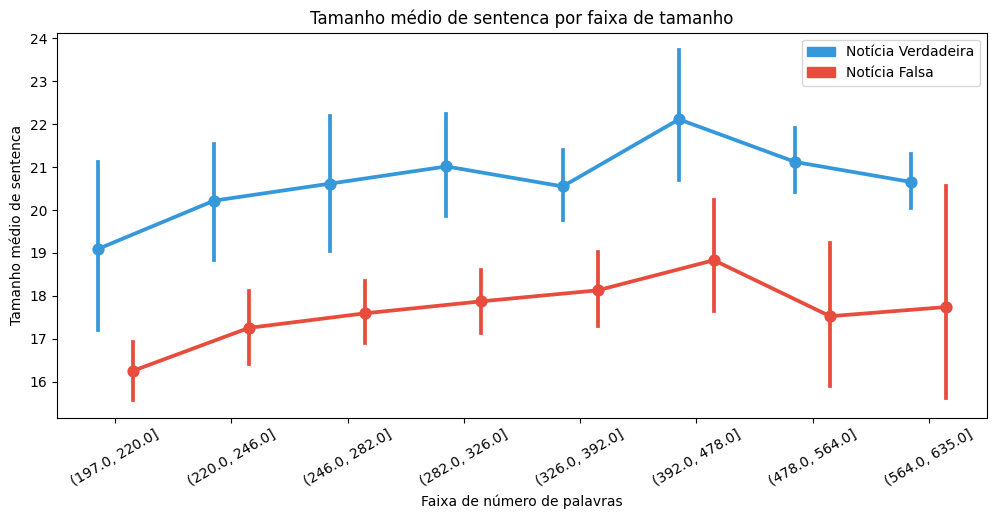

In [11]:
# intervalo de tamanho onde existem textos das duas classes
tabela = comum.pivot_table(index="faixa", columns="rotulo", values="tam_medio_sentenca",
                           aggfunc="mean", observed=True)
tabela.columns = ["media_true", "media_fake"]  # 0 = verdadeira, 1 = falsa
tabela["diferenca"] = tabela["media_fake"] - tabela["media_true"]
display(tabela.round(3))

fig, ax = plt.subplots(figsize=(12, 5))
sns.pointplot(data=comum, x="faixa", y="tam_medio_sentenca", hue="rotulo",
              palette=palette, errorbar=("ci", 95), dodge=0.3, ax=ax)
ax.legend(handles=custom_handles, frameon=True)
ax.set_xlabel("Faixa de número de palavras")
ax.set_ylabel("Tamanho médio de sentenca")
ax.set_title("Tamanho médio de sentenca por faixa de tamanho")
plt.xticks(rotation=30)
plt.show()